# Huấn luyện & Đánh giá Cấp 5 (Dual-Head ResNet Nâng Cấp) trên Google Colab

Notebook này dùng để huấn luyện **Level 5 (`DualHeadResNet`)** trên GPU của Google Colab (**T4 GPU**), tự động trực quan hóa đường cong học tập, đối chiếu với bản Baseline v1 và lưu kết quả về Google Drive.

**Các nâng cấp được áp dụng trong cấu hình mới (`configs/model_resnet.yaml`):**
- Mở rộng **Value Head** (`4 conv filters -> 128 hidden -> Dropout 0.2`) + tăng `value_weight = 2.0`.
- Tăng cường dữ liệu **lật gương ngang `a <-> h`** (`augment_mirror: true`) cho tập Train khi hết quyền nhập thành.
- Chống overfit: `weight_decay = 5e-4`, `label_smoothing = 0.05` (chỉ áp khi train), `grad_clip_norm = 1.0`, `early_stopping_patience = 5`.

**Chuẩn bị trước khi chạy:**
1. Chọn **Runtime -> Change runtime type -> T4 GPU**.
2. Nén thư mục `data/processed` thành `processed.zip` và tải lên Google Drive tại `MyDrive/chess_ai/processed.zip`.

In [1]:
# 1. Kiểm tra GPU và Mount Google Drive
import torch
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
!nvidia-smi --query-gpu=name,memory.total,memory.free --format=csv

from google.colab import drive
drive.mount('/content/drive')

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
name, memory.total [MiB], memory.free [MiB]
Tesla T4, 15360 MiB, 14910 MiB
Mounted at /content/drive


In [6]:
# 2. Cấu hình đường dẫn, Clone/Pull repo và cài đặt thư viện
import os
from pathlib import Path

REPO_URL = 'https://github.com/VoVanTuan284/101_TTNTNC.git'
BRANCH = 'feat-level5-upgrade'  # Đổi thành 'main' sau khi đã merge PR
REPO_DIR = Path('/content/101_TTNTNC')
DRIVE_BASE = Path('/content/drive/MyDrive/data')
DRIVE_DATA_ZIP = Path('/content/drive/MyDrive/data.zip')
DRIVE_OUTPUT_DIR = DRIVE_BASE / 'output_l5'

if not REPO_DIR.exists():
    !git clone -b {BRANCH} {REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git fetch origin
    !git checkout {BRANCH}
    !git pull origin {BRANCH}

%cd {REPO_DIR}
!pip install -q python-chess pyyaml matplotlib

/content/101_TTNTNC
Already on 'feat-level5-upgrade'
Your branch is up to date with 'origin/feat-level5-upgrade'.
From https://github.com/VoVanTuan284/101_TTNTNC
 * branch            feat-level5-upgrade -> FETCH_HEAD
Already up to date.
/content/101_TTNTNC


In [7]:
# 3. Giải nén data/processed sang SSD nội bộ của Colab (/content/) để đọc memmap tốc độ cao
import json
import shutil
import zipfile

PROCESSED_DIR = REPO_DIR / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

if not (PROCESSED_DIR / 'dataset_metadata.json').exists():
    assert DRIVE_DATA_ZIP.exists(), f'Không tìm thấy {DRIVE_DATA_ZIP}. Hãy upload processed.zip lên Google Drive!'
    tmp_extract = Path('/content/_tmp_processed')
    if tmp_extract.exists():
        shutil.rmtree(tmp_extract)
    tmp_extract.mkdir(parents=True)

    with zipfile.ZipFile(DRIVE_DATA_ZIP, 'r') as zf:
        zf.extractall(tmp_extract)

    # Tự động tìm thư mục chứa dataset_metadata.json dù zip có lồng thư mục processed/ hay không
    meta_hits = list(tmp_extract.rglob('dataset_metadata.json'))
    assert meta_hits, 'Không tìm thấy dataset_metadata.json bên trong processed.zip!'
    src_folder = meta_hits[0].parent
    for f in src_folder.iterdir():
        if f.is_file():
            shutil.move(str(f), str(PROCESSED_DIR / f.name))
    shutil.rmtree(tmp_extract)

meta = json.loads((PROCESSED_DIR / 'dataset_metadata.json').read_text(encoding='utf-8'))
print('Tổng mẫu:', f"{meta['total_samples']:,}")
for sp, info in meta['splits'].items():
    print(f"  - {sp:5s}: {info['games']:6,} ván | {info['samples']:7,} mẫu")
!ls -lh data/processed/

Tổng mẫu: 1,000,000
  - train: 37,408 ván | 800,213 mẫu
  - val  :  4,659 ván |  99,432 mẫu
  - test :  4,681 ván | 100,355 mẫu
total 1.1G
-rw-r--r-- 1 root root  822 Nov 23 14:29 dataset_metadata.json
-rw-r--r-- 1 root root 197K Nov 23 14:29 test_actions.dat
-rw-r--r-- 1 root root 111M Nov 23 14:29 test_states.dat
-rw-r--r-- 1 root root 393K Nov 23 14:29 test_values.dat
-rw-r--r-- 1 root root 1.6M Nov 23 14:29 train_actions.dat
-rw-r--r-- 1 root root 880M Nov 23 14:29 train_states.dat
-rw-r--r-- 1 root root 3.1M Nov 23 14:29 train_values.dat
-rw-r--r-- 1 root root 195K Nov 23 14:29 val_actions.dat
-rw-r--r-- 1 root root 110M Nov 23 14:29 val_states.dat
-rw-r--r-- 1 root root 389K Nov 23 14:29 val_values.dat


In [8]:
# 4. Huấn luyện Level 5 trên T4 GPU
# Mẹo: Nếu giữa chừng bị ngắt, đổi RESUME = True để chạy tiếp từ checkpoints/latest.pt
RESUME = False
BATCH_SIZE = 512
NUM_WORKERS = 2

if RESUME and (REPO_DIR / 'checkpoints' / 'latest.pt').exists():
    !python -m chess_ai.training.train_supervised --num-workers {NUM_WORKERS} --batch-size {BATCH_SIZE} --resume checkpoints/latest.pt
else:
    !python -m chess_ai.training.train_supervised --num-workers {NUM_WORKERS} --batch-size {BATCH_SIZE}

Bắt đầu huấn luyện Cấp 5 (Dual-Head ResNet) trên thiết bị: cuda | Train: 800,213 mẫu | Val: 99,432 mẫu | Batch: 512 | Epochs: 1->30
  [Epoch 01/30] TrainLoss: 5.3838 | ValLoss: 4.3073 | Top1Acc: 25.68% | Top3Acc: 47.95% | ValMSE: 0.7299 | 64.8s ★ [BEST]
  [Epoch 02/30] TrainLoss: 4.5302 | ValLoss: 4.0823 | Top1Acc: 28.92% | Top3Acc: 52.81% | ValMSE: 0.7218 | 58.7s ★ [BEST]
  [Epoch 03/30] TrainLoss: 4.3101 | ValLoss: 4.0824 | Top1Acc: 30.69% | Top3Acc: 55.29% | ValMSE: 0.7783 | 58.7s
  [Epoch 04/30] TrainLoss: 4.1679 | ValLoss: 3.8971 | Top1Acc: 31.74% | Top3Acc: 57.01% | ValMSE: 0.7167 | 58.5s ★ [BEST]
  [Epoch 05/30] TrainLoss: 4.0634 | ValLoss: 3.8398 | Top1Acc: 32.71% | Top3Acc: 58.20% | ValMSE: 0.7101 | 59.0s ★ [BEST]
  [Epoch 06/30] TrainLoss: 3.9760 | ValLoss: 3.8071 | Top1Acc: 33.34% | Top3Acc: 58.91% | ValMSE: 0.7094 | 58.9s ★ [BEST]
  [Epoch 07/30] TrainLoss: 3.9042 | ValLoss: 3.8035 | Top1Acc: 33.62% | Top3Acc: 59.47% | ValMSE: 0.7117 | 58.8s ★ [BEST]
  [Epoch 08/30] TrainLo

## 5. Phân tích kết quả & Vẽ biểu đồ huấn luyện
Đọc `results/training/sl_training_metrics.json`, vẽ 4 biểu đồ chi tiết (Total Loss, Policy Loss, Value MSE vs Zero-Baseline, Top-1 & Top-3 Policy Accuracy) và đối chiếu trực tiếp với bản **Level 5 Baseline v1**.

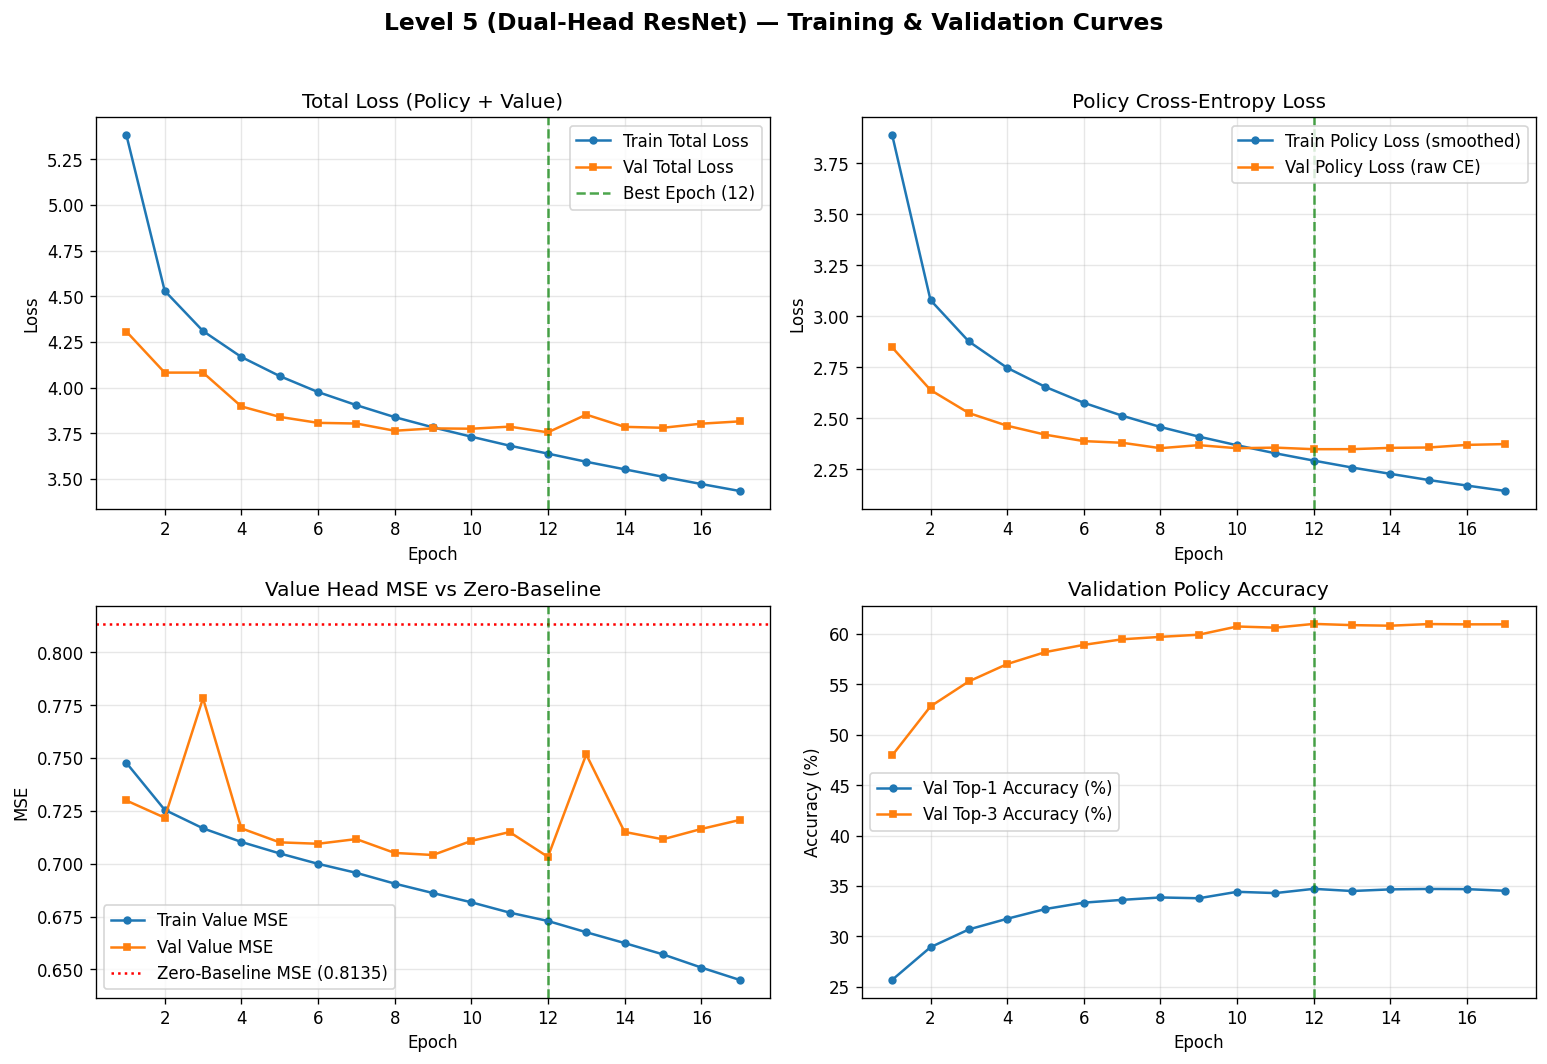

=== TỔNG KẾT TẬP TEST ĐỘC LẬP (SO SÁNH VỚI BASELINE V1) ===
Thiết bị: cuda | Tổng thời gian: 1051.0s | Best Epoch: 12/17
  - Test Top-1 Policy Acc :  34.41%  (v1:  31.14% | chênh: +3.27%)
  - Test Top-3 Policy Acc :  60.74%  (v1:  55.95% | chênh: +4.79%)
  - Test Policy Loss      : 2.3617   (v1: 2.5190  | chênh: -0.1573)
  - Test Value MSE        : 0.6983   (v1: 0.7237  | chênh: -0.0254)
  - Giảm MSE vs Zero-Base :  14.16%  (Zero-Baseline MSE = 0.8135)


In [9]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

metrics_path = Path('results/training/sl_training_metrics.json')
data = json.loads(metrics_path.read_text(encoding='utf-8'))
history = data.get('history', [])
test_eval = data.get('test_evaluation', {})

epochs = [h['epoch'] for h in history]
train_total = [h['train_total_loss'] for h in history]
val_total = [h['val_total_loss'] for h in history]
train_policy = [h['train_policy_loss'] for h in history]
val_policy = [h['val_policy_loss'] for h in history]
train_val_mse = [h['train_value_loss'] for h in history]
val_mse = [h['val_value_mse'] for h in history]
val_top1 = [h['val_top1_policy_acc'] * 100.0 for h in history]
val_top3 = [h['val_top3_policy_acc'] * 100.0 for h in history]

best_idx = min(range(len(val_total)), key=lambda i: val_total[i])
best_ep = epochs[best_idx]
zero_mse = test_eval.get('zero_baseline_mse', 0.81347)

fig, axes = plt.subplots(2, 2, figsize=(13, 9), dpi=120)
fig.suptitle('Level 5 (Dual-Head ResNet) — Training & Validation Curves', fontsize=14, fontweight='bold')

# (1) Total Loss
ax = axes[0, 0]
ax.plot(epochs, train_total, marker='o', markersize=4, label='Train Total Loss')
ax.plot(epochs, val_total, marker='s', markersize=4, label='Val Total Loss')
ax.axvline(best_ep, color='green', linestyle='--', alpha=0.7, label=f'Best Epoch ({best_ep})')
ax.set_title('Total Loss (Policy + Value)')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.grid(True, alpha=0.3)
ax.legend()

# (2) Policy Loss
ax = axes[0, 1]
ax.plot(epochs, train_policy, marker='o', markersize=4, label='Train Policy Loss (smoothed)')
ax.plot(epochs, val_policy, marker='s', markersize=4, label='Val Policy Loss (raw CE)')
ax.axvline(best_ep, color='green', linestyle='--', alpha=0.7)
ax.set_title('Policy Cross-Entropy Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.grid(True, alpha=0.3)
ax.legend()

# (3) Value MSE
ax = axes[1, 0]
ax.plot(epochs, train_val_mse, marker='o', markersize=4, label='Train Value MSE')
ax.plot(epochs, val_mse, marker='s', markersize=4, label='Val Value MSE')
ax.axhline(zero_mse, color='red', linestyle=':', linewidth=1.5, label=f'Zero-Baseline MSE ({zero_mse:.4f})')
ax.axvline(best_ep, color='green', linestyle='--', alpha=0.7)
ax.set_title('Value Head MSE vs Zero-Baseline')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE')
ax.grid(True, alpha=0.3)
ax.legend()

# (4) Top-1 & Top-3 Policy Accuracy
ax = axes[1, 1]
ax.plot(epochs, val_top1, marker='o', markersize=4, label='Val Top-1 Accuracy (%)')
ax.plot(epochs, val_top3, marker='s', markersize=4, label='Val Top-3 Accuracy (%)')
ax.axvline(best_ep, color='green', linestyle='--', alpha=0.7)
ax.set_title('Validation Policy Accuracy')
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy (%)')
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout(rect=[0, 0, 1, 0.96])
fig_path = Path('results/figures/fig_level5_training_curves.png')
fig_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_path, dpi=150)
plt.show()

# Bảng so sánh định lượng với bản Baseline v1
v1 = {
    'top1_policy_acc': 0.31141,
    'top3_policy_acc': 0.55954,
    'policy_loss': 2.51901,
    'value_mse': 0.72372,
    'zero_baseline_mse': 0.81347,
}

print('=== TỔNG KẾT TẬP TEST ĐỘC LẬP (SO SÁNH VỚI BASELINE V1) ===')
print(f"Thiết bị: {data.get('device')} | Tổng thời gian: {data.get('elapsed_sec', 0):.1f}s | Best Epoch: {best_ep}/{data.get('epochs_completed')}")
if test_eval:
    t1, t3 = test_eval['top1_policy_acc'] * 100, test_eval['top3_policy_acc'] * 100
    vmse, ploss = test_eval['value_mse'], test_eval['policy_loss']
    v_gain = (1.0 - vmse / max(1e-8, zero_mse)) * 100
    print(f"  - Test Top-1 Policy Acc : {t1:6.2f}%  (v1: {v1['top1_policy_acc']*100:6.2f}% | chênh: {t1 - v1['top1_policy_acc']*100:+.2f}%)")
    print(f"  - Test Top-3 Policy Acc : {t3:6.2f}%  (v1: {v1['top3_policy_acc']*100:6.2f}% | chênh: {t3 - v1['top3_policy_acc']*100:+.2f}%)")
    print(f"  - Test Policy Loss      : {ploss:6.4f}   (v1: {v1['policy_loss']:6.4f}  | chênh: {ploss - v1['policy_loss']:+.4f})")
    print(f"  - Test Value MSE        : {vmse:6.4f}   (v1: {v1['value_mse']:6.4f}  | chênh: {vmse - v1['value_mse']:+.4f})")
    print(f"  - Giảm MSE vs Zero-Base : {v_gain:6.2f}%  (Zero-Baseline MSE = {zero_mse:.4f})")

In [10]:
# 6. Kiểm tra nhanh inference của Level 5 và Level 7 bằng checkpoint mới
from chess_ai.agents.level5_supervised import Level5SupervisedAgent
from chess_ai.agents.level7_guided_mcts import Level7GuidedMCTSAgent
from chess_ai.core.chess_env import ChessEnv

agent5 = Level5SupervisedAgent(checkpoint_path='checkpoints/best_model.pt', allow_untrained_fallback=False)
agent7 = Level7GuidedMCTSAgent(checkpoint_path='checkpoints/best_model.pt', simulations=400, allow_untrained_fallback=False)

env = ChessEnv()
m5 = agent5.select_move(env)
print(f'Level 5 mở màn: {m5.uci()} | stats: {agent5.last_search_stats}')

m7 = agent7.select_move(env, max_workload=400)
print(f'Level 7 (400 sims) mở màn: {m7.uci()} | stats: {agent7.last_search_stats}')

Level 5 mở màn: e2e3 | stats: {'nodes': 1.0, 'simulations': 0.0, 'depth': 1.0, 'eval': -0.03902208060026169, 'top_prob': 0.19682753086090088, 'time_sec': 0.3776929509999718}
Level 7 (400 sims) mở màn: e2e3 | stats: {'nodes': 400.0, 'simulations': 400.0, 'depth': 7.0, 'eval': 0.009882629951234997, 'root_value': -0.03902208060026169, 'cache_hits': 81.0, 'time_sec': 0.5349801419999949}
